# Exploratory Analysis of Housing Data
**Python** · Dataset `house_data.csv`

This analysis examines the distribution of `MEDV`, its associations with six numerical variables,
and differences between the `CHAS` groups. Run the cells in order from the directory containing
`house_data.csv`.

## 1. Load and inspect the data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.multitest import multipletests

data_path = Path("house_data.csv")
df = pd.read_csv(data_path)
variables = ["RM", "AGE", "DIS", "TAX", "PTRATIO", "LSTAT", "MEDV"]
target = "MEDV"

print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")
display(pd.DataFrame({"Type": df.dtypes, "Missing": df.isna().sum()}))
print(f"Duplicate rows: {df.duplicated().sum()}")
assert set(df["CHAS"].dropna().unique()) == {0, 1}
df["CHAS"] = pd.Categorical(df["CHAS"], categories=[0, 1])
display(df["CHAS"].value_counts(dropna=False).sort_index().to_frame("Count"))

numeric_df = df[variables]
assert all(pd.api.types.is_numeric_dtype(numeric_df[col]) for col in variables)
numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)
complete_data = numeric_df.dropna()
assert len(complete_data) >= 4 and complete_data.nunique().gt(1).all()
print(f"Complete rows for correlations: {len(complete_data)}")

Rows: 506, columns: 14


,Type,Missing
CRIM,float64,0
ZN,float64,0
INDUS,float64,0
CHAS,int64,0
NX,float64,0
RM,float64,0
AGE,float64,0
DIS,float64,0
RAD,int64,0
TAX,float64,0


Duplicate rows: 0


,Count
CHAS,
0,471
1,35


Complete rows for correlations: 506


The dataset has 506 rows and 14 columns, with no missing values or duplicate rows. We treat
`CHAS` as a categorical variable. Descriptive statistics omit invalid values column by column,
and correlations use the same set of complete rows. All 506 observations are available for
every calculation. Potential outliers are retained.

## 2. Descriptive statistics

The sample variance and standard deviation use n − 1 in the variance denominator.
We use linear interpolation in pandas and type 7 quantiles in R. The IQR is Q3 − Q1.

In [2]:
q1 = numeric_df.quantile(0.25, interpolation="linear")
q3 = numeric_df.quantile(0.75, interpolation="linear")
iqr = q3 - q1

summary_table = pd.DataFrame({
    "N": numeric_df.count(), "Mean": numeric_df.mean(),
    "Median": numeric_df.median(), "Variance": numeric_df.var(ddof=1),
    "SD": numeric_df.std(ddof=1), "Min": numeric_df.min(),
    "Q1": q1, "Q3": q3, "Max": numeric_df.max(),
    "Range": numeric_df.max() - numeric_df.min(), "IQR": iqr
})
display(summary_table.round(3))

,N,Mean,Median,Variance,SD,Min,Q1,Q3,Max,Range,IQR
RM,506,6.285,6.208,0.494,0.703,3.561,5.885,6.624,8.780,5.219,0.738
AGE,506,68.575,77.500,792.358,28.149,2.900,45.025,94.075,100.000,97.100,49.050
DIS,506,3.795,3.207,4.434,2.106,1.130,2.100,5.188,12.126,10.997,3.088
TAX,506,408.237,330.000,28404.759,168.537,187.000,279.000,666.000,711.000,524.000,387.000
PTRATIO,506,18.456,19.050,4.687,2.165,12.600,17.400,20.200,22.000,9.400,2.800
LSTAT,506,12.653,11.360,50.995,7.141,1.730,6.950,16.955,37.970,36.240,10.005
MEDV,506,22.533,21.200,84.587,9.197,5.000,17.025,25.000,50.000,45.000,7.975


The median `MEDV` is 21.2, and the middle 50% of values lie between 17.025 and 25.0.
The mean of 22.533 is above the median, and the standard deviation is 9.197 in `MEDV` units.

## 3. Distributions and potential outliers

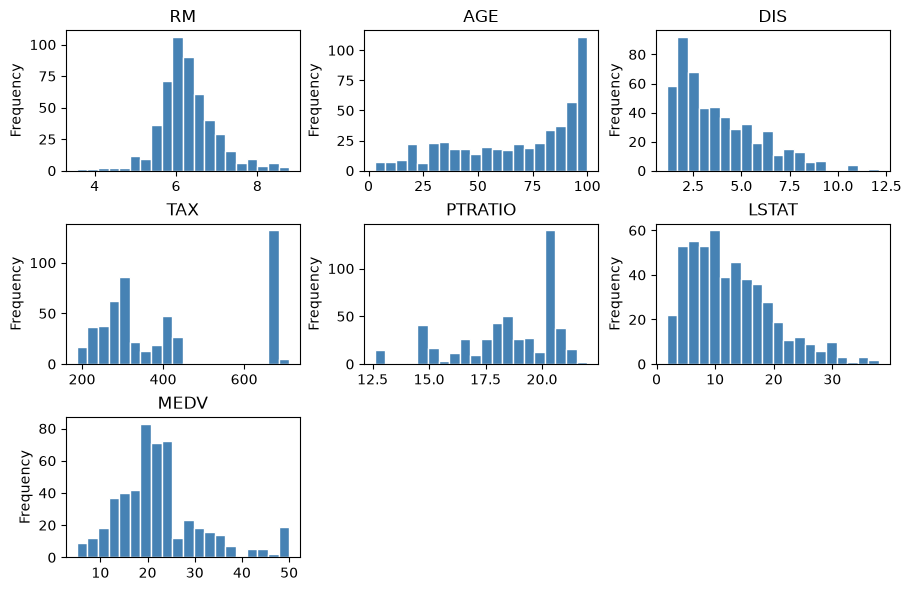

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(9, 5.8), layout="constrained")
for ax, column in zip(axes.flat, variables):
    x = numeric_df[column].dropna()
    bins = np.linspace(x.min(), x.max(), 21)
    ax.hist(x, bins=bins, color="steelblue", edgecolor="white")
    ax.set(title=column, ylabel="Frequency")
for ax in axes.flat[len(variables):]:
    ax.set_visible(False)
plt.show()

- Most `MEDV` values are around 15 to 25, with a long right tail and a cluster at the observed maximum of 50.
- `RM` peaks around 6 and is roughly symmetric near the center, with a few extreme values in both tails.
- `DIS` and `LSTAT` are right-skewed. `AGE` values cluster near the upper end of their range.
- `TAX` has several distinct clusters, with a particularly frequent value of 666.

## 3. Distributions · Boxplots

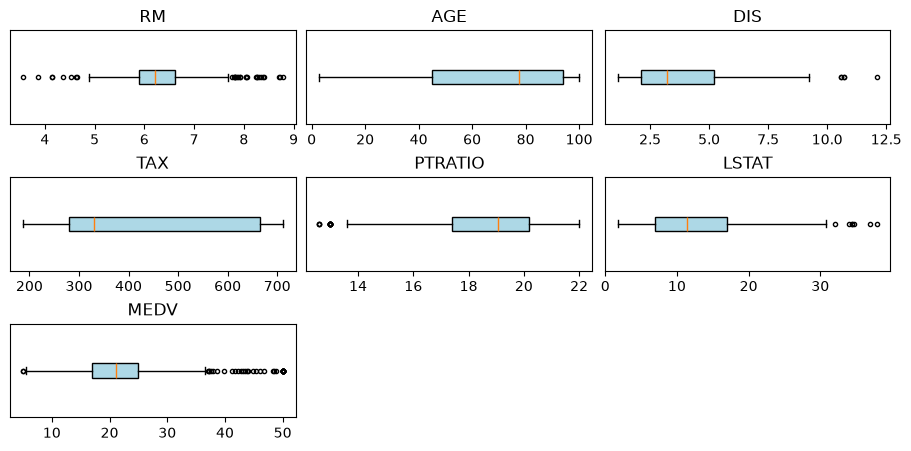

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(9, 4.4), layout="constrained")
for ax, column in zip(axes.flat, variables):
    ax.boxplot(numeric_df[column].dropna(), orientation="horizontal",
               whis=1.5, patch_artist=True,
               boxprops={"facecolor": "lightblue"},
               flierprops={"markersize": 3})
    ax.set(title=column, yticks=[])
for ax in axes.flat[len(variables):]:
    ax.set_visible(False)
plt.show()

Each boxplot shows the median and the middle 50% of values on the variable's own scale.
Base R boxplots use Tukey hinges. The following table applies the quartiles from Step 2 in both
languages so the outlier counts are directly comparable.

## 3. Distributions · The 1.5 × IQR rule

In [5]:
lower_limits = q1 - 1.5 * iqr
upper_limits = q3 + 1.5 * iqr
below = numeric_df.lt(lower_limits)
above = numeric_df.gt(upper_limits)
flagged_rows = (below | above).any(axis=1)

outlier_summary = pd.DataFrame({
    "Lower limit": lower_limits, "Upper limit": upper_limits,
    "Below": below.sum(), "Above": above.sum(),
    "Flagged": below.sum() + above.sum()
})
display(outlier_summary.round(3))
print("Rows flagged in at least one variable:", flagged_rows.sum())
print("MEDV values at the observed maximum:", numeric_df[target].eq(50).sum())

examples = numeric_df.loc[[
    numeric_df["RM"].idxmin(), numeric_df["RM"].idxmax(),
    numeric_df["DIS"].idxmax(), numeric_df[target].idxmin(),
    numeric_df[target].idxmax()
]].copy()
examples.index = ["Min RM", "Max RM", "Max DIS", "Min MEDV", "Max MEDV"]
display(examples.round(3))

,Lower limit,Upper limit,Below,Above,Flagged
RM,4.778,7.731,8,22,30
AGE,-28.550,167.650,0,0,0
DIS,-2.532,9.821,0,5,5
TAX,-301.500,1246.500,0,0,0
PTRATIO,13.200,24.400,15,0,15
LSTAT,-8.058,31.963,0,7,7
MEDV,5.062,36.963,2,38,40


Rows flagged in at least one variable: 68
MEDV values at the observed maximum: 16


,RM,AGE,DIS,TAX,PTRATIO,LSTAT,MEDV
Min RM,3.561,87.9,1.613,666.0,20.2,7.12,27.5
Max RM,8.780,82.9,1.905,666.0,20.2,5.29,21.9
Max DIS,6.728,36.1,12.126,187.0,17.0,4.50,30.1
Min MEDV,5.453,100.0,1.490,666.0,20.2,30.59,5.0
Max MEDV,7.489,90.8,1.971,403.0,14.7,1.73,50.0


For `MEDV`, 38 values are above the upper limit and 2 are below the lower limit.
The maximum of 50 appears 16 times, suggesting a possible measurement ceiling.
The smallest and largest `RM` values (3.561 and 8.780) have `MEDV` values of 27.5 and 21.9,
respectively. These observations sit far out on the horizontal axis in the scatterplot.
All records remain in the analysis.

## 4. Compare the CHAS groups

,count,mean,median,std,IQR
CHAS,,,,,
0,471,22.094,20.9,8.831,8.20
1,35,28.440,23.3,11.817,12.05


Mean difference (1 - 0): 6.346


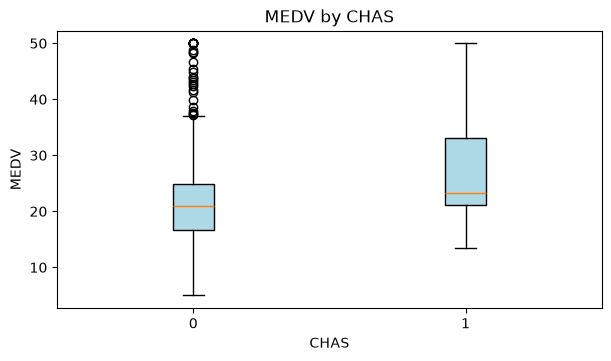

In [6]:
groups = numeric_df[target].groupby(df["CHAS"], observed=True)
group_summary = groups.agg(["count", "mean", "median", "std"])
group_summary["IQR"] = groups.quantile(0.75) - groups.quantile(0.25)
display(group_summary.round(3))
mean_difference = group_summary.loc[1, "mean"] - group_summary.loc[0, "mean"]
print(f"Mean difference (1 - 0): {mean_difference:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.boxplot([groups.get_group(i).dropna() for i in [0, 1]], tick_labels=["0", "1"],
           patch_artist=True, boxprops={"facecolor": "lightblue"})
ax.set(xlabel="CHAS", ylabel=target, title="MEDV by CHAS")
plt.show()

In the `CHAS = 1` group, the mean `MEDV` is 6.346 higher and the median is 2.4 higher.
The group also has a larger standard deviation and IQR. The distributions overlap,
and the groups differ considerably in size (471 observations for `CHAS = 0` and 35 for
`CHAS = 1`). The comparison is descriptive and does not adjust for other variables.

## 5. Scatterplots and local smoothing

Each scatterplot uses a local linear smoother with a span of 0.70.
The `LSTAT` plot also includes a curve with a span of 0.30.

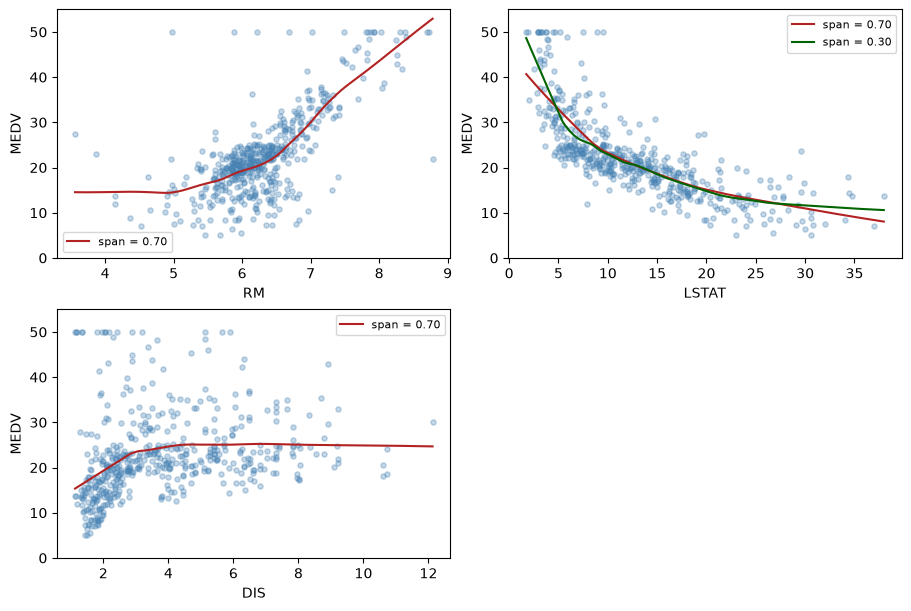

In [7]:
predictors = ["RM", "LSTAT", "DIS"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")

for ax, predictor in zip(axes.flat, predictors):
    pair_data = numeric_df[[predictor, target]].dropna()
    x, y = pair_data[predictor], pair_data[target]
    x_grid = np.linspace(x.min(), x.max(), 150)
    ax.scatter(x, y, color="steelblue", alpha=0.32, s=14)
    spans = [0.70, 0.30] if predictor == "LSTAT" else [0.70]
    for span, color in zip(spans, ["firebrick", "darkgreen"]):
        trend = lowess(y, x, frac=span, it=0, xvals=x_grid)
        ax.plot(x_grid, trend, color=color, label=f"span = {span:.2f}")
    ax.set(xlabel=predictor, ylabel=target, ylim=(0, 55))
    ax.legend(loc="best", fontsize=8)
axes[1, 1].set_visible(False)
plt.show()

## 5. Scatterplots · Interpretation

- **RM.** `MEDV` generally rises with `RM`. Its spread is greater in the top quarter of `RM`
  than in the middle two quarters. Extreme points such as `RM = 8.780` with `MEDV = 21.9`
  may affect the smooth near the ends, where observations are sparse.
- **LSTAT.** `MEDV` drops sharply as `LSTAT` increases and then declines more gradually.
  At low `LSTAT`, the vertical spread is wider and some values reach 50. The 0.30 span
  captures a sharper initial drop than the 0.70 span.
- **DIS.** `MEDV` rises at first and then levels off. At short distances, low values and values
  of 50 occur together. The vertical spread narrows as `DIS` increases, and observations
  are sparse at the far right.

## 6. Correlation matrices

All three methods use the same 506 rows, variable order, and color scale from −1 to 1.
The heatmaps show coefficients rounded to two decimal places.

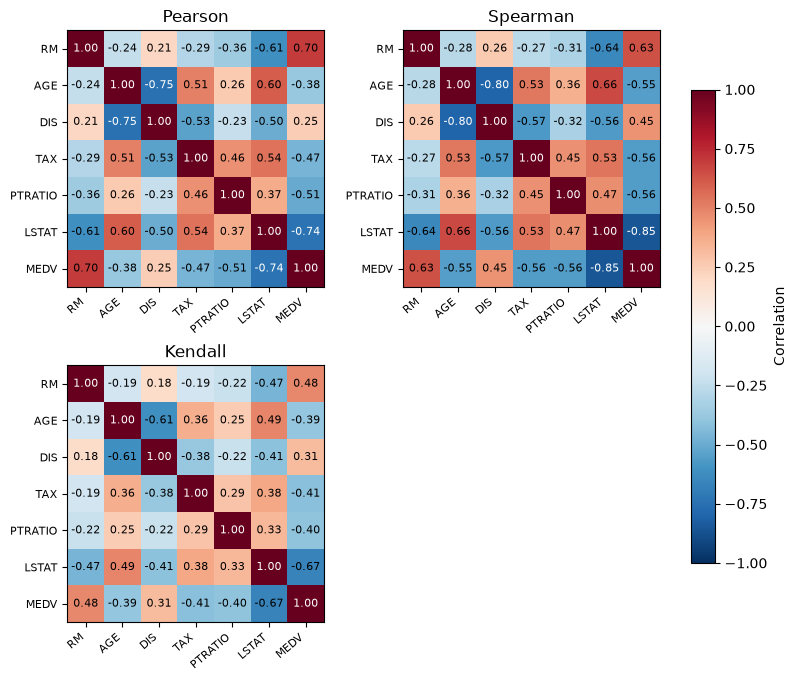

In [8]:
methods = ["pearson", "spearman", "kendall"]
correlation_matrices = {method: complete_data.corr(method=method)
                        for method in methods}
fig, axes = plt.subplots(2, 2, figsize=(8, 6.7), layout="constrained")
for ax, method in zip(axes.flat, methods):
    matrix = correlation_matrices[method]
    img = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set(title=method.capitalize(), xticks=range(len(variables)),
           yticks=range(len(variables)), yticklabels=variables)
    ax.set_xticklabels(variables, rotation=40, ha="right", fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    for (row, col), value in np.ndenumerate(matrix.to_numpy()):
        color = "white" if abs(value) >= 0.70 else "black"
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                fontsize=8, color=color)
axes[1, 1].set_visible(False)
fig.colorbar(img, ax=axes, shrink=0.8, label="Correlation")
plt.show()

## 6. Correlations · Associations with MEDV

In [9]:
target_correlations = pd.DataFrame({
    method.capitalize(): matrix.loc[:, target].drop(target)
    for method, matrix in correlation_matrices.items()
})
display(target_correlations.round(3))

,Pearson,Spearman,Kendall
RM,0.695,0.634,0.483
AGE,-0.377,-0.548,-0.388
DIS,0.250,0.446,0.313
TAX,-0.469,-0.562,-0.415
PTRATIO,-0.508,-0.556,-0.399
LSTAT,-0.738,-0.853,-0.669


- `LSTAT` has the strongest association with `MEDV` across all three matrices.
  Spearman's ρ (−0.853) captures the predominantly monotonic, curved decline in the scatterplot.
  Pearson's r (−0.738) summarizes the linear association.
- Spearman's ρ (0.446) is also suitable for `DIS`. The scatterplot rises and then levels off,
  and Pearson's r (0.250) indicates a weaker linear association. The scatterplot shows how
  the spread and trend change across the range of `DIS`.
- `RM` has a strong positive Pearson correlation (0.695). The absolute value of Kendall's τ
  is smaller than Spearman's ρ for all six pairs. Kendall's τ is based on concordant and
  discordant pairs, so the two coefficients have different interpretations.

## 7. Pearson tests and uncertainty

For each predictor, we run a two-sided test of whether its population Pearson correlation
with `MEDV` is zero. The individual approximate 95% confidence intervals use Fisher's
transformation. The Benjamini-Hochberg (BH) correction treats the six tests as one family.

In [10]:
records = []
for predictor in variables[:-1]:
    test = stats.pearsonr(complete_data[predictor], complete_data[target])
    interval = test.confidence_interval(confidence_level=0.95)
    records.append([predictor, len(complete_data), test.statistic,
                    interval.low, interval.high, test.pvalue])

results = pd.DataFrame(records, columns=[
    "Variable", "N", "r", "CI_low", "CI_high", "p_value"
])
results["p_BH"] = multipletests(results["p_value"], method="fdr_bh")[1]
results["Reject_BH"] = results["p_BH"] <= 0.05
display(results.style.format({
    "r": "{:.4f}", "CI_low": "{:.4f}", "CI_high": "{:.4f}",
    "p_value": "{:.3e}", "p_BH": "{:.3e}"
}).hide(axis="index"))

Variable,N,r,CI_low,CI_high,p_value,p_BH,Reject_BH
RM,506,0.6954,0.6474,0.7378,2.487e-74,7.462e-74,True
AGE,506,-0.3770,-0.4494,-0.2996,1.570e-18,1.884e-18,True
DIS,506,0.2499,0.1664,0.3299,1.207e-08,1.207e-08,True
TAX,506,-0.4685,-0.5339,-0.3976,5.638e-29,8.457e-29,True
PTRATIO,506,-0.5078,-0.5697,-0.4401,1.610e-34,3.219e-34,True
LSTAT,506,-0.7377,-0.7750,-0.6952,5.081e-88,3.049e-87,True


After BH correction, all six null hypotheses are rejected at the 0.05 level.
`LSTAT` has the largest absolute Pearson correlation (r = −0.738). `DIS` has the weakest
Pearson correlation (r = 0.250) and an adjusted p-value of about 1.21 × 10⁻⁸. The p-value
measures evidence against the null hypothesis. The coefficient and its confidence interval
describe the size and uncertainty of the association.

## 8. Python and R comparison and conclusions

**Python and R.** Comparing outputs at full precision confirmed agreement on the data checks,
descriptive statistics, outlier counts, group summaries, all three correlation matrices,
and all six Pearson tests. The displayed values use different rounding formats.

**Data handling and smoothing.** No values needed imputation, and all rows were complete.
Linear interpolation in pandas and type 7 quantiles in R give the same quartiles and IQR
limits. Base R boxplots use Tukey hinges. Python's LOWESS and R's LOESS both use local linear
regression without robust reweighting. R evaluates the local fit directly
(`surface = "direct"`). On the same 150-point grid, the fitted curves differ by at most
8 × 10⁻¹³ `MEDV` units, which is consistent with floating-point rounding. Other LOESS
settings, such as interpolation, can produce different curves.

**Main findings.** `MEDV` has a right tail, and 16 observations are at its maximum of 50.
The strongest associations are negative with `LSTAT` and positive with `RM`.
The `CHAS = 1` group has a mean `MEDV` that is 6.346 higher, greater variability,
and fewer observations in this sample.

**Limitations.** A possible ceiling in `MEDV`, changing spread in the scatterplots,
and sensitivity to individual observations limit interpretation. Classical Pearson inference
assumes independent observations and approximate bivariate normality. If observations close
to one another are similar, the true uncertainty may be larger. The correlations and group
differences describe unadjusted associations in this dataset.